# 04 — Uplift Models: S-, T-, and X-Learners

**Question.** How do three standard meta-learners compare on the active dataset? We fit each on the same training split with the same logistic base learner, score the same test split, and inspect the resulting uplift distributions, agreement, and Qini.

All three estimate the **conditional average treatment effect**
$\tau(x) = P(Y = 1 \mid X = x, T = 1) - P(Y = 1 \mid X = x, T = 0)$
but they construct the estimate differently.

## 1. The three meta-learners

- **S-learner.** One outcome model trained with treatment as an extra feature.   Score each row twice — once with $T=1$, once with $T=0$ — and take the   difference. Cheap; can underfit the treatment effect when treatment is one   feature among many.
- **T-learner.** Two separate outcome models, one per arm. Uplift is the   difference of predictions. Avoids the underfitting failure mode but pays   full statistical cost twice and can be noisy when one arm is small.
- **X-learner.** Builds on the T-learner: imputes pseudo-effects on each arm   using the opposite-arm model, then regresses those pseudo-effects on   features. Often more stable when arms are imbalanced.


In [1]:
import sys
from pathlib import Path

_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_marketing.notebook_utils import setup_notebook, save_figure
from uplift_marketing.data import load_default_uplift_data

config = setup_notebook()
RANDOM_STATE = 42

dataset = load_default_uplift_data(config.raw_dir, random_state=RANDOM_STATE)
data = dataset.data
print(f"data source: {dataset.source} ({len(data):,} rows)")
print(f"observed treated share: {data['treatment'].mean():.3f} "
      f"(expected {dataset.expected_treated_share:.3f})")
print(f"feature columns to exclude: {dataset.extra_excluded}")


data source: hillstrom (64,000 rows)
observed treated share: 0.667 (expected 0.667)
feature columns to exclude: ['customer_id']


In [2]:
from sklearn.model_selection import train_test_split

from uplift_marketing.features import (
    infer_feature_spec,
    split_features_treatment_outcome,
)
from uplift_marketing.models import SLearner, TLearner, XLearner
from uplift_marketing.evaluation import qini_curve, area_under_qini

spec = infer_feature_spec(data, extra_excluded=dataset.extra_excluded)
x, treatment, y = split_features_treatment_outcome(data, spec)

x_tr, x_te, t_tr, t_te, y_tr, y_te = train_test_split(
    x, treatment, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=treatment.astype(str) + "_" + y.astype(str),
)
models = {
    "s_learner": SLearner(spec=spec, random_state=RANDOM_STATE),
    "t_learner": TLearner(spec=spec, random_state=RANDOM_STATE),
    "x_learner": XLearner(spec=spec, random_state=RANDOM_STATE),
}
for m in models.values():
    m.fit(x_tr, t_tr, y_tr)
uplifts = pd.DataFrame({name: m.predict_uplift(x_te) for name, m in models.items()})
uplifts.describe().T

,count,mean,std,min,25%,50%,75%,max
s_learner,19200.0,0.153876,0.013926,0.090815,0.147462,0.159016,0.164700,0.166540
t_learner,19200.0,0.040150,0.116069,-0.246534,-0.049599,0.049942,0.129425,0.407506
x_learner,19200.0,0.022548,0.058758,-0.139323,-0.021433,0.023325,0.066341,0.210485


## 2. Distributions of predicted uplift

An overlaid histogram makes two things visible: how concentrated each model is around zero (a thin distribution often signals a model collapsing onto the marginal effect) and how the tails differ (where targeting decisions live).

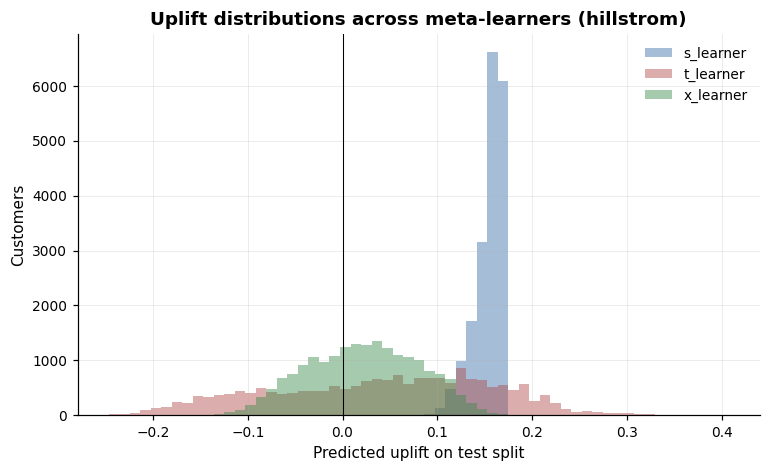

In [3]:
fig, ax = plt.subplots()
lo, hi = float(uplifts.values.min()), float(uplifts.values.max())
bins = np.linspace(lo, hi, 60)
for name, color in zip(["s_learner", "t_learner", "x_learner"], ["#3b6ea8", "#b04a4a", "#3b8a4a"]):
    ax.hist(uplifts[name], bins=bins, alpha=0.45, label=name, color=color)
ax.axvline(0, color="black", linewidth=0.7)
ax.set_xlabel("Predicted uplift on test split")
ax.set_ylabel("Customers")
ax.set_title(f"Uplift distributions across meta-learners ({dataset.source})")
ax.legend()
save_figure(fig, "04_uplift_distributions")
plt.show()

## 3. Agreement between models

If two models agree on the *ranking* they will produce the same campaign at any fixed budget; only the magnitudes will differ. A scatter of T- vs X-learner uplift, with the 45-degree line, shows where the X-learner's pseudo-effect regression pulls scores away from the raw two-model difference.

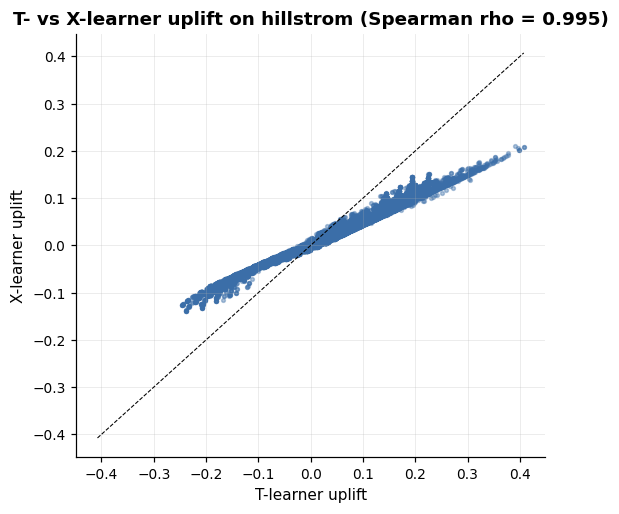

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 5.0))
ax.scatter(uplifts["t_learner"], uplifts["x_learner"], s=6, alpha=0.4, color="#3b6ea8")
lim = float(np.max(np.abs(uplifts[["t_learner", "x_learner"]].to_numpy())))
ax.plot([-lim, lim], [-lim, lim], color="black", linewidth=0.7, linestyle="--")
ax.set_xlabel("T-learner uplift")
ax.set_ylabel("X-learner uplift")
rho = uplifts[["t_learner", "x_learner"]].corr(method="spearman").iloc[0, 1]
ax.set_title(
    f"T- vs X-learner uplift on {dataset.source} (Spearman rho = {rho:.3f})"
)
save_figure(fig, "04_t_vs_x_uplift")
plt.show()

## 4. Qini overlay

Distribution shape only matters if it improves the *ranking*. The Qini curve translates each model's score into a campaign-relevant quantity: how many incremental conversions we expect at each contact fraction.

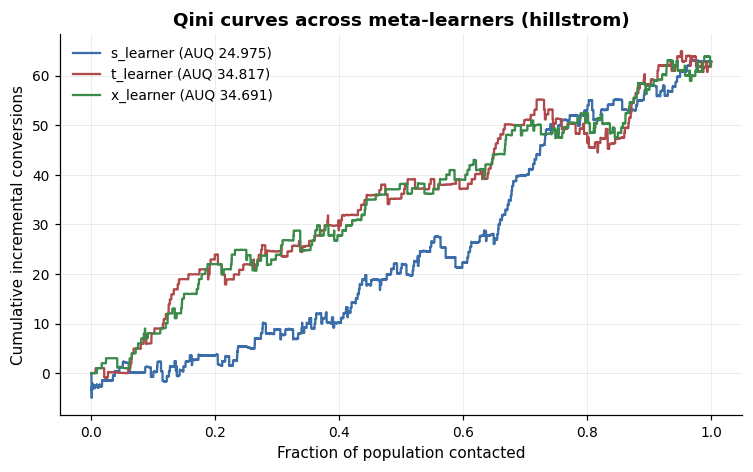

,model,area_under_qini
1,t_learner,34.816576
2,x_learner,34.691095
0,s_learner,24.974558


In [5]:
rows = []
fig, ax = plt.subplots()
colors = {"s_learner": "#3b6ea8", "t_learner": "#b04a4a", "x_learner": "#3b8a4a"}
for name, scores in uplifts.items():
    curve = qini_curve(
        outcome=y_te.to_numpy(),
        treatment=t_te.to_numpy(),
        uplift_score=scores.to_numpy(),
    )
    auq = area_under_qini(curve)
    rows.append({"model": name, "area_under_qini": auq})
    ax.plot(
        curve["population_fraction"],
        curve["incremental_gain"],
        label=f"{name} (AUQ {auq:.3f})",
        color=colors[name],
    )
ax.set_xlabel("Fraction of population contacted")
ax.set_ylabel("Cumulative incremental conversions")
ax.set_title(f"Qini curves across meta-learners ({dataset.source})")
ax.legend()
save_figure(fig, "04_qini_overlay")
plt.show()
pd.DataFrame(rows).sort_values("area_under_qini", ascending=False)

## 5. Takeaway

- The T- and X-learners typically agree on ranking (high Spearman correlation). The X-learner's distribution is tighter — its second-stage regression pulls noisy pseudo-effects back toward the mean.
- The S-learner produces a much narrower distribution because the treatment indicator is one feature among many; if its AUQ is much lower than T/X, treat that as the underfitting signature, not a tuning problem.
- On rare-event data the absolute levels of T- and X-learner uplift can drift well above the dataset's naive ATE — logistic predictions are not always well-calibrated when conversions are rare. The downstream Qini and policy work uses *ranking*, which is more robust than absolute calibration; notebook 06 quantifies the calibration gap explicitly.
- AUQ provides a single number to pick a default ranker for downstream policy work; the next notebook uses it but reads it alongside decile and top-k policy views, which are less noisy on this kind of data.
